# Particle physics
*Tracks in a solenoid: from hits to momentum*

A charged particle in a magnetic field bends, and the bend tells you its momentum. This page sends tracks through a solenoid, records a hit in each of ten cylindrical layers, adds the hits into detector cells, and fits each track's curvature to get its transverse momentum. Each layer is a thin slab of material that scatters the track a little, with correlated position and angle kicks. One lane is one track. It then asks how much the fitted momentum moves when one layer is misplaced.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, on_device, plot_style, show, to_numpy, xp
plot_style()

## The detector, once

Ten thin cylindrical layers at radii 0.1, 0.2, ... 1.0 m surround the beam line. A uniform solenoid field of `B = 2 T` points along the beam. A particle of transverse momentum `pT` (GeV) and charge `q = +-1` leaves the beam line and moves on a circle of radius `pT / (0.3 B)` metres in the transverse plane. It crosses the layer at radius `r` at the azimuth `phi0 - q asin(kappa r / 2)`, with curvature `kappa = 0.3 B / pT` per metre.

- Each layer records one hit with a Gaussian error of 100 µm along the layer. The model leaves out energy loss, the longitudinal coordinate and track finding.
- **Multiple scattering.** Every layer is a slab of material, 0.5 mm of silicon (radiation length 93.7 mm, so `x / X0 = 0.53 %`). A charged particle crossing it is deflected by many small random kicks. **Highland's formula** gives the width of the projected angle, `theta0 = 13.6 MeV / (beta c p) z sqrt(x / X0) (1 + 0.038 ln(x / X0))`, here with `beta = 1` and `p = pT` (the track stays in the transverse plane). Inside a slab of thickness `t` the track also drifts sideways, and the standard covariance of that drift `y` and the angle `theta` is `theta0^2 [[t^2/3, t/2], [t/2, 1]]`: the two are correlated, which is why one draw gives both, by `m.mvn_sample`. The kicks add up along the track: a kick in one layer moves every later hit by the angle times the distance. The slab is crossed at normal incidence (the slant adds about 1 % at 2 GeV). It makes the resolution `sigma(pT)/pT = sqrt((a pT)^2 + b^2)`: a term `a pT` from the hit error and a constant `b` from scattering, which dominates at low momentum.
- A hit also leaves an amount of energy, drawn from an exponential law of mean 1 in arbitrary units (a stand-in for the Landau-like deposit in a thin layer). Each layer is cut into 64 azimuth **cells**, and every hit adds one to the occupancy of its cell and its energy to the cell's energy. That is a keyed sum, like [Particle binning](08_particle_binning); here the keys come from tracks that are fitted in the same pass.
- The fit: a straight least-squares fit of the hit arc coordinate `y = r phi` to `a + b r + c r^2`, with the vertex free. The curvature is `c = -q kappa / 2`, so `pT = 0.3 B / (2 |c|)`. The least-squares solution is linear in the hits: `c` is a fixed weighted sum of them, with weights from the design matrix.

Declare the detector's words as a `KernelKind` once: the track number, its momentum, charge and starting azimuth, an alignment error that moves one layer's hit, and the slab's thickness and radiation length.

In [3]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Index, Mutable, Param, Scalar, Table, Vector
from hawk.ext import DATA_ONLY, KernelKind

NLAY, NPHI = 10, 64                                       # layers, and azimuth cells per layer
NC = NLAY * NPHI
TWO_PI = 2 * np.pi
RADIUS = 0.1 * np.arange(1, NLAY + 1)                      # layer radii (m): 0.1, 0.2, ... 1.0
SIGMA, BFIELD = 1e-4, 2.0                                  # hit resolution along the layer (m), solenoid field (T)
THICK, X_RAD = 0.5e-3, 93.7e-3                             # a layer's thickness and the radiation length of its material (m): silicon

# the fit is a straight least-squares fit of the hit arc coordinate y = r phi to a + b r + c r^2: the curvature c is
# a fixed weighted sum of the hits, c = sum_i weight_i y_i, with weights from the pseudo-inverse of the design matrix
design = np.stack([np.ones(NLAY), RADIUS, RADIUS**2], axis=1)
WEIGHT = np.linalg.pinv(design)[2]


class Tracker(KernelKind, slug="tracker"):
    seed: Index         # the track number: with a draw counter, it fixes every random number
    pt: Scalar          # transverse momentum (GeV)
    charge: Scalar      # +1 or -1
    phi0: Scalar        # azimuth the track leaves the beam line at (rad)
    kick: Index         # the layer whose hit is moved (0..9), -1 for none
    shift: Scalar       # by how much (m): the alignment error
    sigma: Param        # hit resolution (m)
    bfield: Param       # solenoid field (T)
    thickness: Param    # thickness of each layer's material (m); 0 switches multiple scattering off
    x_rad: Param        # radiation length of that material (m)
    guard = DATA_ONLY

Tracker

__main__.Tracker

## One track

The kernel flies one track through the layers with a loop over the ten layers. Per layer it computes the hit azimuth, adds `weight * r * phi` to the running fit, draws the hit's energy, and adds both into the cell with `hawk.scatter(sink)[cell] += value`. The azimuth is kept unwrapped, because the fit needs a continuous angle; only the cell key wraps it back into one turn.

Multiple scattering is two running numbers, the sideways `offset` the earlier kicks have built up and the direction `angle` they have added. At each layer the offset grows by the angle times the distance since the last layer, then one `m.mvn_sample` draw adds the slab's own drift and angle kick, and the offset moves the hit. The 2 x 2 covariance is built in the kernel with `m.mat`, in units of `y / t` so that its entries stay of order `theta0^2`. With `thickness = 0` the covariance is zero, the draw fails by design and returns zeros, and the kernel is the one without scattering.

The radii and fit weights are tables shared by every lane. The hit-azimuth formula is a plain Python helper: it runs once, when the kernel is traced. Random numbers come from hawk's counter-based generator, so a track gives the same hits on every run and on every device.

In [4]:
def unwrapped_zeros():
    return m.vec(*[0.0] * NLAY)


def scatter_kick(seed, i, pt, thickness, x_rad):
    # one slab's random kick: the sideways drift and the angle, drawn together from Highland's covariance
    ratio = m.where(thickness > 0.0, thickness / x_rad, 1.0)
    theta0 = m.where(thickness > 0.0, 0.0136 / pt * m.sqrt(ratio) * (1.0 + 0.038 * m.log(ratio)), 0.0)
    cov = m.mat([[theta0 * theta0 / 3.0, theta0 * theta0 / 2.0], [theta0 * theta0 / 2.0, theta0 * theta0]])      # in units of (y / t, theta)
    z = m.mvn_sample(seed, 2 * NLAY + i, m.vec(0.0, 0.0), cov)
    return thickness * z[0], z[1]


def hit_angle(seed, i, radius, phi0, charge, kappa, sigma, kick, shift, scatter):
    # azimuth of the measured hit in layer i: the helix crosses radius r at phi0 - q asin(kappa r / 2); `scatter` is the sideways offset
    r = radius.at(i)
    miss = sigma * m.random.normal(seed, 2 * i) + m.where(kick == i, shift, 0.0) + scatter
    return phi0 - charge * m.asin(0.5 * kappa * r) + miss / r


@Tracker
def reconstruct(seed, pt, charge, phi0, kick, shift, sigma, bfield, thickness, x_rad, radius: Table[Scalar], weight: Table[Scalar],
                pt_fit: Mutable[Scalar], e_track: Mutable[Scalar], phi_hit: Mutable[Vector[NLAY]],
                occupancy: Mutable["cell":NC], energy: Mutable["cell":NC]):
    kappa = 0.3 * bfield / pt                              # curvature (1/m): the radius is pt / (0.3 B)
    curve = 0.0
    e_sum = 0.0
    hits = unwrapped_zeros()
    offset = 0.0
    angle = 0.0
    behind = 0.0
    for i in range(NLAY):
        r = radius.at(i)
        offset = offset + angle * (r - behind)             # the earlier kicks carry the track sideways
        behind = r
        drift, kink = scatter_kick(seed, i, pt, thickness, x_rad)
        offset = offset + drift
        angle = angle + kink
        phi = hit_angle(seed, i, radius, phi0, charge, kappa, sigma, kick, shift, offset)
        curve = curve + weight.at(i) * r * phi             # the fit, one hit at a time
        e = m.random.exponential(seed, 2 * i + 1, 1.0)     # energy the hit leaves in the layer (arbitrary units)
        u = phi / TWO_PI
        cell = i * NPHI + m.index((u - m.floor(u)) * NPHI, NPHI)      # the azimuth wraps; the cell key must too
        hawk.scatter(occupancy)[cell] += 1.0
        hawk.scatter(energy)[cell] += e
        e_sum = e_sum + e
        hits[i] = phi
    pt_fit = 0.15 * bfield / m.abs(curve)                  # c = -q kappa / 2, so pt = 0.3 B / (2 |c|)
    e_track = e_sum
    phi_hit = hits


reconstruct

<Kernel reconstruct slots=19>

## A sweep of momenta

Ten momenta from 2 to 40 GeV, 2000 tracks each: 20 000 lanes, one call. It runs twice on the same tracks: once with scattering off (`thickness = 0`, the detector the first checks below describe) and once with the slabs on. Most tracks start in three narrow bundles of azimuth, like jets, and the rest are spread evenly. `eagle.deploy(reconstruct).run(...)` takes the planes and tables by name and returns the outputs by name; the cell sinks start at zero and come back as one array for the whole call.

In [5]:
PT = np.geomspace(2.0, 40.0, 10)                           # GeV
PER = 2000                                                 # tracks per momentum
n = len(PT) * PER
rng = np.random.default_rng(11)
lane_pt = np.repeat(PT, PER)
lane_charge = rng.choice([-1.0, 1.0], n)
centres = np.array([0.8, 2.6, 4.4])                        # three narrow bundles of tracks, plus a flat background
phi_start = np.where(rng.random(n) < 0.7, rng.choice(centres, n) + 0.25 * rng.normal(size=n), rng.uniform(0, TWO_PI, n)) % TWO_PI
lane_seed = np.arange(n)

tracker = eagle.deploy(reconstruct)


sweep = dict(seed=lane_seed, pt=lane_pt, charge=lane_charge, phi0=phi_start, kick=np.full(n, -1), shift=np.zeros(n),
             sigma=SIGMA, bfield=BFIELD, x_rad=X_RAD, radius=RADIUS, weight=WEIGHT)
out_plain, out = ({k: np.asarray(v) for k, v in tracker.run(thickness=t, **sweep).items()} for t in (0.0, THICK))   # scattering off, then on
fitted_plain = out_plain["pt_fit"].reshape(len(PT), PER)
fitted = out["pt_fit"].reshape(len(PT), PER)
print(f"{n} tracks, {NLAY} layers, {NC} cells; fitted pt, mean ratio to the true value: {np.mean(fitted_plain / PT[:, None]):.4f} without scattering, {np.mean(fitted / PT[:, None]):.4f} with it")

20000 tracks, 10 layers, 640 cells; fitted pt, mean ratio to the true value: 0.9986 without scattering, 0.9986 with it


## Check the cell sums, then the resolution

Five checks. The first four are about the detector without scattering, on the run with `thickness = 0`; the fifth is about scattering.

- **Cell sums.** Every track crosses every layer, so each layer must hold exactly one hit per track and the cells together `tracks x layers` hits. The energy in the cells must add up to the energy the tracks report. Both are kept by construction of the sum, and they catch a lost or doubled hit. A separate check rebuilds the cell keys in NumPy from the returned hit azimuths and counts them: that tests the keys.
- **Resolution, exact.** For a linear fit the covariance is known: the error of the curvature is `sigma sqrt(sum weight_i^2)`. The spread of the fitted `1/pT` should match it, to the number of standard errors the sample allows. It is `1/pT` that is Gaussian, so that is what the page compares.
- **Resolution, Gluckstern.** For `N` equally spaced hits over a length `L` the exact finite-`N` form is `sigma(pT) / pT = sigma pT / (0.3 B L^2) sqrt(720 (N-1)^3 / ((N-2) N (N+1) (N+2)))`. It is the same number as the least-squares covariance, so the page asserts the two agree to rounding: a closed-form check of `WEIGHT`. The familiar large-`N` form `sqrt(720 / (N + 4))` is printed too, to show how far it is off at `N = 10`.
- **The bias of the fitted `pT`.** The fit is a parabola in `r`, not a full helix, and that has a price: the `asin` term of the hit position leaves a small curvature error that falls as `1/pT^2`. It is computed once in NumPy without noise. The noise adds a second, smaller effect: `1/pT` is Gaussian, so `pT` is skewed upward by about the relative variance. At high momentum that skew is smaller than the sample can resolve, so the page asks only that the bias there be consistent with it within the sample's error.

- **Multiple scattering.** Three tests. The draws first: a small kernel takes many kicks from `scatter_kick`, and their covariance must match Highland's `theta0^2 [[t^2/3, t/2], [t/2, 1]]`, correlation 0.87 included. Then the resolution: with the slabs on, the fitted `1/pT` has the variance of the hit error plus a scattering part, and the scattering part is known exactly because the fit is linear in the hits: a kick `(dy, dtheta)` in layer `j` moves the fitted curvature by `dy S0_j + dtheta S1_j`, with `S0_j` the sum of the weights from layer `j` out, and `S1_j` the same sum weighted by each layer's distance beyond layer `j`. Last, the constant: a fit of `spread^2 = (a pT)^2 + b^2` over the ten momenta must give a `b` equal to that sum, within its fit error.

The resolution law without scattering is first order in `pT`: the error doubles when the momentum doubles. The page fits its slope on log axes.

In [6]:
import math

# 1. cell sums are conserved
occ, edep = out["occupancy"], out["energy"]
per_layer = occ.reshape(NLAY, NPHI).sum(axis=1)
assert (per_layer == n).all() and occ.sum() == n * NLAY
print(f"occupancy: every layer holds {n} hits, {int(occ.sum())} in all = {n} tracks x {NLAY} layers")
by_track = math.fsum(out["e_track"])
assert abs(edep.sum() - by_track) < 1e-9 * by_track
print(f"energy: the cells add up to {edep.sum():.3f}, the tracks to {by_track:.3f} (relative gap {abs(edep.sum() - by_track) / by_track:.1e})")

# 2. the cell keys are right: rebuild them from the returned hit azimuths with NumPy
u = out["phi_hit"] / TWO_PI
cells = (np.arange(NLAY)[:, None] * NPHI + np.minimum(((u - np.floor(u)) * NPHI).astype(int), NPHI - 1)).ravel()
assert np.array_equal(np.bincount(cells, minlength=NC).astype(float), occ)
print("the occupancy matches a NumPy count of the same hits, cell by cell")

# 3. the momentum resolution, without scattering: the spread of the fitted curvature against the references
curvature_error = PT[:, None] / fitted_plain - 1                  # error of the fitted 1 / pt, relative: it is Gaussian
spread = curvature_error.std(axis=1)
kappa = 0.3 * BFIELD / PT
least_squares = SIGMA * np.sqrt((WEIGHT**2).sum()) / (0.5 * kappa)          # sigma_c / |c|, with c = sum weight_i y_i
L = RADIUS[-1] - RADIUS[0]
N = NLAY
gluckstern = SIGMA * PT / (0.3 * BFIELD * L**2) * np.sqrt(720 * (N - 1) ** 3 / ((N - 2) * N * (N + 1) * (N + 2)))   # exact, finite N
gluckstern_large_n = SIGMA * PT / (0.3 * BFIELD * L**2) * np.sqrt(720 / (N + 4))
assert np.abs(gluckstern / least_squares - 1).max() < 1e-12, "the finite-N Gluckstern form is the least-squares covariance"
print(f"finite-N Gluckstern = least-squares covariance to {np.abs(gluckstern / least_squares - 1).max():.0e}; "
      f"the large-N form is {(gluckstern_large_n[0] / gluckstern[0] - 1) * 100:.1f} % high at N = {N}")
stat = 1 / np.sqrt(2 * (PER - 1))
print(f"relative error of 1/pt (3.2e-2 means 3.2 %), fitted / least-squares covariance:")
for p, s, a in zip(PT, spread, least_squares):
    print(f"  pt = {p:5.1f} GeV: {s:.4f}  {a:.4f}")
assert (np.abs(spread / least_squares - 1) < 4 * stat).all(), spread / least_squares
print(f"fitted spread within {np.abs(spread / least_squares - 1).max() * 100:.1f} % of the least-squares covariance (four standard errors = {4 * stat * 100:.1f} %)")
slope = np.polyfit(np.log(PT), np.log(spread), 1)[0]
assert abs(slope - 1) < 0.05, slope
print(f"fitted order: the resolution grows as pt^{slope:.2f} (Gluckstern: 1)")

# 4. the bias of the fitted pt: the parabola's own model error (no noise) plus the skew of a Gaussian 1/pt
c_free = -(WEIGHT * RADIUS * np.arcsin(0.5 * kappa[:, None] * RADIUS)).sum(axis=1)       # noise-free fitted c, for q = +1
bias_model = 0.15 * BFIELD / np.abs(c_free) / PT - 1
bias = (fitted_plain / PT[:, None] - 1).mean(axis=1)
bias_expected = (1 + bias_model) * (1 + least_squares**2) - 1                             # model error, then the skew (about the variance)
bias_se = (fitted_plain / PT[:, None]).std(axis=1) / np.sqrt(PER)
assert (np.abs(bias - bias_expected) < 4 * bias_se).all(), (bias, bias_expected, bias_se)
print("mean error of the fitted pt, measured / noise-free parabola bias / expected with the skew (%):")
for p, b, f, e in zip(PT, bias, bias_model, bias_expected):
    print(f"  pt = {p:5.1f} GeV: {b * 100:+.3f}  {f * 100:+.3f}  {e * 100:+.3f}")

occupancy: every layer holds 20000 hits, 200000 in all = 20000 tracks x 10 layers
energy: the cells add up to 200387.656, the tracks to 200387.656 (relative gap 0.0e+00)
the occupancy matches a NumPy count of the same hits, cell by cell
finite-N Gluckstern = least-squares covariance to 4e-16; the large-N form is 1.7 % high at N = 10
relative error of 1/pt (3.2e-2 means 3.2 %), fitted / least-squares covariance:
  pt =   2.0 GeV: 0.0029  0.0029
  pt =   2.8 GeV: 0.0041  0.0040
  pt =   3.9 GeV: 0.0058  0.0056
  pt =   5.4 GeV: 0.0079  0.0079
  pt =   7.6 GeV: 0.0112  0.0110
  pt =  10.6 GeV: 0.0154  0.0153
  pt =  14.7 GeV: 0.0211  0.0214
  pt =  20.6 GeV: 0.0291  0.0298
  pt =  28.7 GeV: 0.0411  0.0416
  pt =  40.0 GeV: 0.0580  0.0580
fitted spread within 2.4 % of the least-squares covariance (four standard errors = 6.3 %)
fitted order: the resolution grows as pt^0.99 (Gluckstern: 1)
mean error of the fitted pt, measured / noise-free parabola bias / expected with the skew (%):
  pt =  

## Multiple scattering

Now the run with the slabs on. First the draws, then the resolution, then its constant term.

In [7]:
# the draws: many kicks from scatter_kick, covariance against Highland's
@Tracker
def kicks(seed, pt, charge, phi0, kick, shift, sigma, bfield, thickness, x_rad, drift: Mutable[Scalar], kink: Mutable[Scalar]):
    drift, kink = scatter_kick(seed, 0, pt, thickness, x_rad)


nk = 200_000
kk = eagle.deploy(kicks).run(seed=np.arange(nk), pt=np.full(nk, 5.0), charge=np.ones(nk), phi0=np.zeros(nk), kick=np.full(nk, -1),
                             shift=np.zeros(nk), sigma=SIGMA, bfield=BFIELD, thickness=THICK, x_rad=X_RAD)
ratio_x = THICK / X_RAD
theta0 = lambda p: 0.0136 / p * np.sqrt(ratio_x) * (1 + 0.038 * np.log(ratio_x))      # Highland, beta = 1, p = pt
t0 = theta0(5.0)
sample = np.cov(np.stack([kk["drift"], kk["kink"]]))
want = t0**2 * np.array([[THICK**2 / 3, THICK / 2], [THICK / 2, 1.0]])
stat_k = np.sqrt(2 / (nk - 1))
assert abs(sample[0, 0] / want[0, 0] - 1) < 4 * stat_k and abs(sample[1, 1] / want[1, 1] - 1) < 4 * stat_k
corr = sample[0, 1] / np.sqrt(sample[0, 0] * sample[1, 1])
assert abs(corr - np.sqrt(3) / 2) < 4 / np.sqrt(nk)
print(f"{nk} kicks at 5 GeV: theta0 = {t0 * 1e3:.3f} mrad (Highland), sample {np.sqrt(sample[1, 1]) * 1e3:.3f} mrad; "
      f"drift {np.sqrt(sample[0, 0]) * 1e6:.2f} um against {np.sqrt(want[0, 0]) * 1e6:.2f}; correlation {corr:.3f} against {np.sqrt(3) / 2:.3f}")

# the resolution with the slabs on: hit error plus the exact scattering sum
S0 = np.cumsum(WEIGHT[::-1])[::-1]                                                         # sum of the weights from layer j outward
S1 = np.array([(WEIGHT[j + 1:] * (RADIUS[j + 1:] - RADIUS[j])).sum() for j in range(NLAY)])    # the same, weighted by the lever arm
ms_variance = lambda p: theta0(p) ** 2 * (S0**2 * THICK**2 / 3 + S0 * S1 * THICK + S1**2).sum()
scatter_term = np.sqrt(ms_variance(PT)) / (0.5 * kappa)                                    # b: the relative error of 1/pt from scattering
spread_ms = (PT[:, None] / fitted - 1).std(axis=1)
expected = np.sqrt(least_squares**2 + scatter_term**2)
assert (np.abs(spread_ms / expected - 1) < 4 * stat).all(), spread_ms / expected
print("relative error of 1/pt (%), with scattering: fitted / sqrt(hit^2 + scattering^2) / hit term / scattering term")
for p, s, e, a, b in zip(PT, spread_ms, expected, least_squares, scatter_term):
    print(f"  pt = {p:5.1f} GeV: {s * 100:.3f}  {e * 100:.3f}  {a * 100:.3f}  {b * 100:.3f}")

# the constant term: spread^2 = (a pt)^2 + b^2, fitted over the ten momenta
weights = 1 / (spread_ms**2 * np.sqrt(2 / (PER - 1)))                                      # the variance of a squared spread is 2 / (N - 1) of itself squared
(slope_sq, b_sq), cov_fit = np.polyfit(PT**2, spread_ms**2, 1, w=weights, cov="unscaled")
b_fit, b_exact = np.sqrt(b_sq), scatter_term[0]
assert abs(b_sq - b_exact**2) < 4 * np.sqrt(cov_fit[1, 1]), (b_sq, b_exact**2, cov_fit[1, 1])
assert abs(np.sqrt(slope_sq) / (least_squares[0] / PT[0]) - 1) < 0.05
print(f"fit of spread^2 = (a pt)^2 + b^2: b = {b_fit * 100:.3f} % (from the sum over the layers: {b_exact * 100:.3f} %, "
      f"error of the fit on b^2 {np.sqrt(cov_fit[1, 1]) / b_exact**2 * 100:.0f} %), a = {np.sqrt(slope_sq) * 100:.3f} % per GeV (hit error alone: {least_squares[0] / PT[0] * 100:.3f})")
log_factor = 1 + 0.038 * np.log(ratio_x)                                                   # Highland's log term, applied to each thin layer
b_without_log = b_exact / log_factor
pdg = 0.016 / (0.3 * BFIELD * RADIUS[-1]) * np.sqrt(NLAY * ratio_x)                       # PDG: 0.016 sqrt(L / X0) / (L p); L = 1 m, total thickness N t
assert abs(pdg / b_without_log - 1) < 0.05
print(f"PDG's estimate 0.016 sqrt(N x/X0) / (0.3 B L) = {pdg * 100:.3f} %; the exact sum without the log factor {b_without_log * 100:.3f} % "
      f"({abs(pdg / b_without_log - 1) * 100:.1f} % from it); Highland's log factor per layer is {log_factor:.3f}, which gives the {b_exact * 100:.3f} % above")
crossover = b_exact / (least_squares[0] / PT[0])
print(f"the two terms are equal at pt = {crossover:.1f} GeV: below it scattering sets the resolution, above it the hit error does")

200000 kicks at 5 GeV: theta0 = 0.159 mrad (Highland), sample 0.159 mrad; drift 0.05 um against 0.05; correlation 0.866 against 0.866
relative error of 1/pt (%), with scattering: fitted / sqrt(hit^2 + scattering^2) / hit term / scattering term
  pt =   2.0 GeV: 0.588  0.588  0.290  0.512
  pt =   2.8 GeV: 0.638  0.653  0.405  0.512
  pt =   3.9 GeV: 0.769  0.762  0.565  0.512
  pt =   5.4 GeV: 0.928  0.939  0.788  0.512
  pt =   7.6 GeV: 1.231  1.212  1.099  0.512
  pt =  10.6 GeV: 1.620  1.616  1.532  0.512
  pt =  14.7 GeV: 2.184  2.198  2.138  0.512
  pt =  20.6 GeV: 2.945  3.026  2.982  0.512
  pt =  28.7 GeV: 4.172  4.191  4.160  0.512
  pt =  40.0 GeV: 5.850  5.825  5.803  0.512
fit of spread^2 = (a pt)^2 + b^2: b = 0.509 % (from the sum over the layers: 0.512 %, error of the fit on b^2 3 %), a = 0.144 % per GeV (hit error alone: 0.145)
PDG's estimate 0.016 sqrt(N x/X0) / (0.3 B L) = 0.616 %; the exact sum without the log factor 0.639 % (3.6 % from it); Highland's log factor per 

PDG's closed form for the scattering term, `0.016 / (0.3 B L) sqrt(L / X0)`, is for a continuous scatterer of total thickness `N t`. Its `0.016` is Highland's `0.0136` times about `sqrt(1.43)`, the geometric factor of a fit through the material. It uses Highland's width for the whole thickness, without the log term. The page applies Highland's formula to each thin layer instead, where `x / X0` is small, so the log term `1 + 0.038 ln(x / X0)` is 0.80 and lowers the constant by 20 %. The exact sum without that factor is within 4 % of PDG's form; with it, it is the 0.51 % the fit found.

## The gradient an alignment engineer wants

If one layer sits a little off its nominal position, how much does the fitted momentum move? `shift` is an extra displacement of the hit along the lane's `kick` layer: a shift `s` of layer `k` is a rotation of that layer about the beam axis by `s / r_k`, the classic sagitta weak mode. `hawk.diff.jvp(reconstruct, wrt=("shift",))` derives the kernel that pushes a unit shift through the whole fit. `eagle.deploy` takes the kernel and its derivative together and runs either by name. The lanes are 50 tracks per layer at each of four momenta, half of each charge.

Three checks. A central finite difference of the same fit, in float64 with a 1 µm step, tests the exact derivative of what the kernel computes. The closed form: the fit is linear in the hits, so a shift `s` in layer `k` changes `c` by `weight_k s`, and `pT = 0.15 B / |c|` gives `d pT / d s = -pT weight_k / c`. And in the variable the rotation actually moves, `q / pT = -c / (0.15 B)`: `d(q/pT) / d s = -weight_k / (0.15 B)`, the same for every track, whatever its momentum or charge. A rotation biases `q / pT` for every track by the same amount, so positive and negative tracks move in opposite directions in `pT`.

In [8]:
from hawk import Kernel
from hawk.diff import jvp

reconstruct_jvp = Kernel("reconstruct_jvp", jvp(reconstruct, wrt=("shift",)))
tracker, forward = eagle.deploy([reconstruct, reconstruct_jvp])

G = 50                                                     # tracks per layer and momentum for the alignment study
PT_ALIGN = np.array([5.0, 10.0, 20.0, 40.0])               # GeV
layers = np.repeat(np.arange(NLAY), len(PT_ALIGN) * G)
ng = len(layers)
pts = np.tile(np.repeat(PT_ALIGN, G), NLAY)
charges = np.where(np.arange(ng) % 2 == 0, 1.0, -1.0)      # half of each
common = dict(seed=np.tile(np.arange(G), NLAY * len(PT_ALIGN)), pt=pts, charge=charges, phi0=np.tile(phi_start[:G], NLAY * len(PT_ALIGN)),
              kick=layers, sigma=SIGMA, bfield=BFIELD, thickness=THICK, x_rad=X_RAD, radius=RADIUS, weight=WEIGHT)
slope_hawk = np.asarray(forward.run(shift=np.zeros(ng), dot_shift=np.ones(ng), **common)["dot_pt_fit"])       # GeV per m

H = 1e-6                                                   # m
up = np.asarray(tracker.run(shift=np.zeros(ng) + H, **common)["pt_fit"])
down = np.asarray(tracker.run(shift=np.zeros(ng) - H, **common)["pt_fit"])
slope_fd = (up - down) / (2 * H)
TOL_GRAD = 1e-6
gap = np.abs(slope_hawk - slope_fd).max() / np.abs(slope_fd).max()
assert gap < TOL_GRAD, gap
print(f"d pt_fit / d shift over {ng} lanes (10 layers x {len(PT_ALIGN)} momenta x {G} tracks): worst gap to central differences {gap:.1e} of the largest value < {TOL_GRAD:g}")

# the closed form: the fit is linear in the hits, so d c / d shift_k = weight_k, and pt = 0.15 B / |c|
base = np.asarray(tracker.run(shift=np.zeros(ng), **common)["pt_fit"])
curve = -charges * 0.15 * BFIELD / base                    # the fitted c has the sign of -q
closed = -base / curve * WEIGHT[layers]
TOL_CLOSED = 1e-9
gap_closed = np.abs(slope_hawk - closed).max() / np.abs(closed).max()
assert gap_closed < TOL_CLOSED, gap_closed
print(f"against the closed form -pt_fit weight_k / c: worst gap {gap_closed:.1e} of the largest value < {TOL_CLOSED:g}")

# in q / pt the derivative is one number per layer: the same at every momentum and for both charges
dq = -charges * slope_hawk / base**2                       # d(q / pt) / d shift, per GeV per m
q_closed = -WEIGHT[layers] / (0.15 * BFIELD)
gap_q = np.abs(dq - q_closed).max() / np.abs(q_closed).max()
assert gap_q < TOL_CLOSED, gap_q
per_um = -WEIGHT / (0.15 * BFIELD) * 1e-6 * 1e3            # TeV^-1 per micron, one value per layer
print(f"d(q/pt) / d shift is -weight_k / (0.15 B) for all {ng} lanes (four momenta, both charges): worst gap {gap_q:.1e} of the largest value < {TOL_CLOSED:g}")
print("a 1 µm rotation of layer k moves q/pt of every track by (1/TeV), layers 1 to 10:", per_um.round(4))
end = int(np.argmax(np.abs(per_um)))
print(f"a 100 µm shift of layer {end + 1} biases q/pt by {per_um[end] * 100:+.2f} 1/TeV: a 10 GeV mu+ moves from 10 GeV to "
      f"{1 / (0.1 + per_um[end] * 100 * 1e-3):.2f} GeV, and a mu- to {1 / (0.1 - per_um[end] * 100 * 1e-3):.2f} GeV")

d pt_fit / d shift over 2000 lanes (10 layers x 4 momenta x 50 tracks): worst gap to central differences 1.2e-07 of the largest value < 1e-06
against the closed form -pt_fit weight_k / c: worst gap 2.4e-16 of the largest value < 1e-09
d(q/pt) / d shift is -weight_k / (0.15 B) for all 2000 lanes (four momenta, both charges): worst gap 2.3e-16 of the largest value < 1e-09
a 1 µm rotation of layer k moves q/pt of every track by (1/TeV), layers 1 to 10: [-0.0076 -0.0025  0.0013  0.0038  0.0051  0.0051  0.0038  0.0013 -0.0025
 -0.0076]
a 100 µm shift of layer 1 biases q/pt by -0.76 1/TeV: a 10 GeV mu+ moves from 10 GeV to 10.08 GeV, and a mu- to 9.92 GeV


A shift of a layer is a rotation of that layer, and it biases `q / pT` of every track by the same amount, whatever the momentum, with the sign set by the layer. The end layers matter most. Because the bias is on `q / pT`, tracks of opposite charge move opposite ways in `pT`, which is why the page reports the derivative in `q / pT` and not the size of `d pT / d s`.

## The picture

Left: a transverse event display. 200 tracks of 2 to 5.4 GeV cross the ten layers (circles); each dot is a hit, and each arc is the track's true path, coloured by `q pT` on one fixed scale: positive tracks bend one way, negative the other, and the lower the momentum the stronger the bend. The amber cells are the detector cells those tracks lit up. Right: the resolution against momentum. The fitted spread (dots) follows the exact covariance with scattering, the hit error and the scattering added in quadrature (solid). The dotted line is the constant scattering term `b`, which sets the resolution at low momentum; the dashed line is the hit-error term alone, the finite-`N` Gluckstern formula, a straight line on log axes.


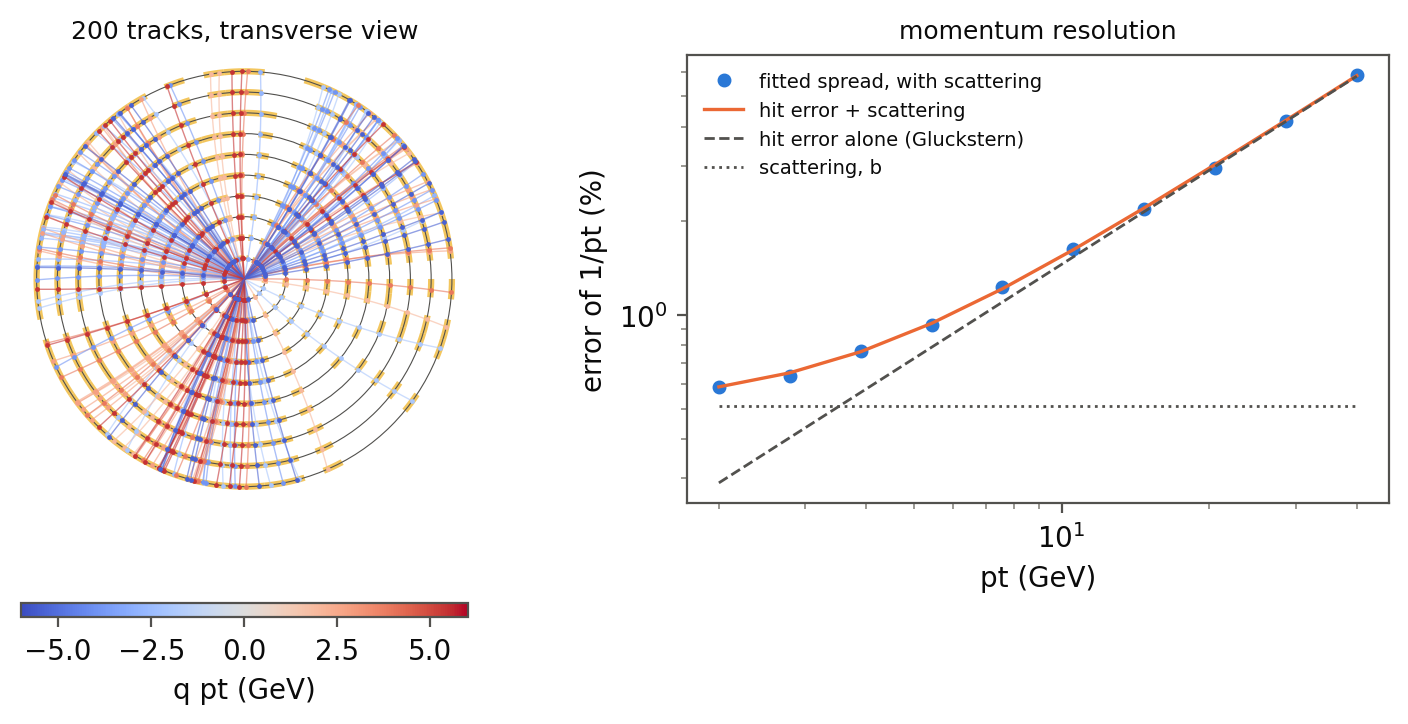
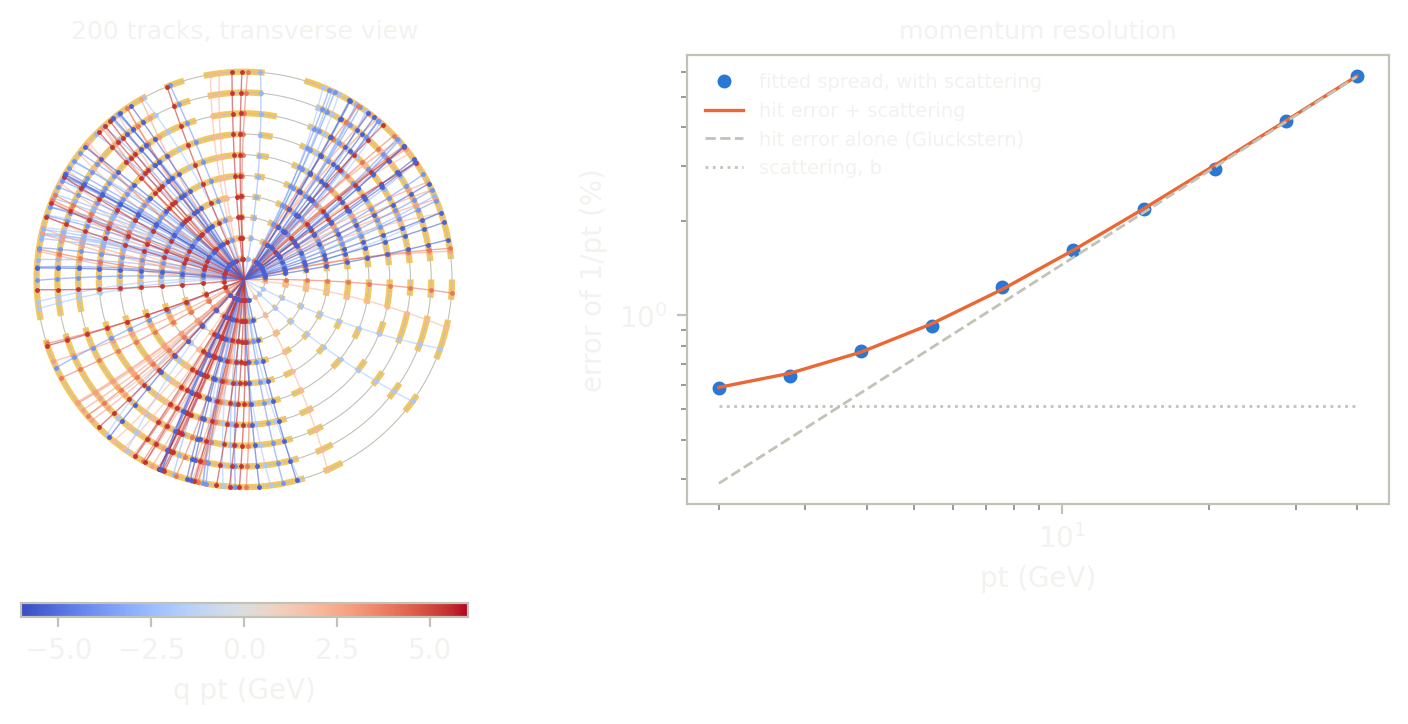

In [9]:
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Circle, Wedge

# the event: 50 tracks from each of the four lowest momenta, where the bending is visible
LOW = 4
pick = np.random.default_rng(3)
shown = np.concatenate([k * PER + pick.choice(PER, 50, replace=False) for k in range(LOW)])
q_pt = lane_charge[shown] * lane_pt[shown]
norm = TwoSlopeNorm(vcenter=0.0, vmin=-6.0, vmax=6.0)
cmap = plt.get_cmap("coolwarm")
hit_phi = out["phi_hit"][:, shown]                                       # (layer, track)
frac = hit_phi / TWO_PI - np.floor(hit_phi / TWO_PI)
lit = np.minimum((frac * NPHI).astype(int), NPHI - 1)                    # the cell each shown hit fell in

fig, (left, right) = plt.subplots(1, 2, figsize=(7.4, 3.5), gridspec_kw={"width_ratios": [1.0, 1.1]}, constrained_layout=True)
for layer in range(NLAY):
    for cell in np.unique(lit[layer]):
        left.add_patch(Wedge((0, 0), RADIUS[layer] + 0.015, cell * 360 / NPHI, (cell + 1) * 360 / NPHI, width=0.03,
                             facecolor="#f0b429", edgecolor="none", alpha=0.75, zorder=1))
    left.add_patch(Circle((0, 0), RADIUS[layer], fill=False, lw=0.4, ec="#898781", zorder=2))
r_line = np.linspace(0.0, RADIUS[-1], 80)
for j, lane in enumerate(shown):
    kap = 0.3 * BFIELD / lane_pt[lane]
    ang = phi_start[lane] - lane_charge[lane] * np.arcsin(0.5 * kap * r_line)
    colour = cmap(norm(q_pt[j]))
    left.plot(r_line * np.cos(ang), r_line * np.sin(ang), lw=0.5, color=colour, alpha=0.6, zorder=3)
    left.scatter(RADIUS * np.cos(hit_phi[:, j]), RADIUS * np.sin(hit_phi[:, j]), s=3, color=colour, zorder=4, linewidths=0)
left.set_xlim(-1.08, 1.08); left.set_ylim(-1.08, 1.08); left.set_aspect("equal")
left.set_xticks([]); left.set_yticks([]); left.set_title("200 tracks, transverse view", fontsize=9)
for side in left.spines.values():
    side.set_visible(False)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=left, label="q pt (GeV)", location="bottom", shrink=0.7, pad=0.02, aspect=30)
right.loglog(PT, spread_ms * 100, "o", ms=4, color="#2a78d6", label="fitted spread, with scattering")
right.loglog(PT, expected * 100, "-", lw=1.2, color="#eb6834", label="hit error + scattering")
right.loglog(PT, gluckstern * 100, "--", lw=1.0, color="#898781", label="hit error alone (Gluckstern)")
right.loglog(PT, scatter_term * 100, ":", lw=1.0, color="#898781", label="scattering, b")
right.set_xlabel("pt (GeV)"); right.set_ylabel("error of 1/pt (%)"); right.set_title("momentum resolution", fontsize=9)
right.legend(frameon=False, fontsize=7)
show(fig, f"Two panels. Left: a transverse event display of {len(shown)} tracks of {PT[0]:.0f} to {PT[LOW - 1]:.1f} GeV leaving the centre through ten concentric layers; each track is an arc bending clockwise or anticlockwise, coloured by charge times momentum from -6 to +6 GeV, with a dot at each hit and the detector cells those hits fell in lit amber. Right: the relative error of one over transverse momentum against momentum on log axes, starting at {spread_ms[0] * 100:.2f} percent at {PT[0]:g} GeV, flattening towards the scattering floor of {scatter_term[0] * 100:.2f} percent at low momentum, and rising as a straight line to {spread_ms[-1] * 100:.1f} percent at {PT[-1]:g} GeV, with the hit-error plus scattering curve through the dots, the hit-error line below it and the flat scattering line.")

## A bigger run, when a GPU is there

This cell runs only when a GPU is present; on a CPU runtime it prints that and does nothing. The same kernel and the same call run on device arrays: two million tracks of 10 GeV. At that size the spread of `1/pT` must match the exact covariance within 1%, and each layer must still hold one hit per track.

In [10]:
if gpu_available():
    big = 2_000_000
    k = xp.arange(big)
    rng_big = np.random.default_rng(5)
    got = tracker.run(seed=k, pt=xp.full(big, 10.0), charge=xp.asarray(rng_big.choice([-1.0, 1.0], big)),
                      phi0=xp.asarray(rng_big.uniform(0, TWO_PI, big)), kick=xp.full(big, -1, dtype=xp.int64), shift=xp.zeros(big),
                      sigma=SIGMA, bfield=BFIELD, thickness=THICK, x_rad=X_RAD, radius=xp.asarray(RADIUS), weight=xp.asarray(WEIGHT))
    assert on_device(got["pt_fit"]), "the result is a device array: the kernel ran on the GPU"
    err_big = 10.0 / to_numpy(got["pt_fit"]) - 1
    want = np.sqrt((SIGMA * np.sqrt((WEIGHT**2).sum()) / (0.5 * 0.3 * BFIELD / 10.0)) ** 2 + scatter_term[0] ** 2)      # hit error and scattering
    assert abs(err_big.std() / want - 1) < 0.01, (err_big.std(), want)
    occ_big = to_numpy(got["occupancy"]).reshape(NLAY, NPHI).sum(axis=1)
    assert (occ_big == big).all()
    print(f"{big} tracks on the GPU: spread {err_big.std():.5f} against hit error plus scattering {want:.5f}; every layer holds {big} hits")
else:
    print("no GPU here; the sweep stays at", n, "tracks")

2000000 tracks on the GPU: spread 0.01539 against hit error plus scattering 0.01538; every layer holds 2000000 hits


## What just happened

- `Tracker` named the track, its momentum, charge and starting azimuth, and the alignment error once; `reconstruct` flies one track, adds its hits into the cells and fits its momentum, in those names.
- The cell sums were conserved, and the cell keys matched a NumPy count of the same hits.
- Each layer scattered the track: `m.mvn_sample` drew the slab's drift and angle together from Highland's covariance, and the sample matched it, correlation included. The fitted resolution is then the hit error and the scattering in quadrature, and a fit of the ten momenta gave the constant term 0.51 %, equal to the exact sum over the layers. Without Highland's log factor that sum is 0.64 %, within 4 % of PDG's `0.016 sqrt(N x/X0) / (0.3 B L)` (0.62 %); applying the log factor to each thin layer lowers it to 0.51 %. Scattering sets the resolution below about 3.5 GeV.
- Without scattering, the spread of the fitted `1/pT` matched the exact least-squares covariance within the number of standard errors the sample allows, and that covariance is the finite-`N` Gluckstern formula to rounding. The resolution grew as `pT` to the power 0.99. The bias of the fitted `pT` was the parabola's own model error at low momentum (-0.76 % at 2 GeV) and, at high momentum, consistent with the expected skew of a Gaussian `1/pT` within the sample's error: the sample cannot tell that skew from none.
- `jvp` gave `d pT / d s` for each layer through the whole fit. It matched central differences and the closed form, and in `q / pT` it is one number per layer, the same at every momentum and for both charges.
- The picture is an event display, 200 tracks bending through the layers with their hit cells lit, beside the resolution curve.

## Try this

Halve the hit resolution (`SIGMA = 5e-5`) and the resolution curve should halve. Or double the field and watch it halve again. Or cut the layers to 6 (`NLAY = 6`): the large-`N` line moves 3.7 % away from the fit, while the finite-`N` line stays on it. Each is a one-line change; the checks tell you what held.

## Next

[Particle binning](08_particle_binning) has the keyed sums on their own, with the other policies. [Combustion](13_combustion) takes a gradient through a stop.